<a href="https://colab.research.google.com/github/miiiray/banking-intent-ai/blob/main/notebooks/01_veri_inceleme.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Libraries and datas**

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split  # scikit-learn kütüphanesinden veriyi bölmeye yarayan hazır fonksiyonu alıyoruz

url = "https://raw.githubusercontent.com/PolyAI-LDN/task-specific-datasets/master/banking_data/"
# veriyi tablo olarak işlemek için
train = pd.read_csv(url + "train.csv")
test = pd.read_csv(url + "test.csv")
#verileri yükle

print(train.shape, test.shape)
train.head() #ilk 5ini görüntüle



(10003, 2) (3080, 2)


,text,category
0,I am still waiting on my card?,card_arrival
1,What can I do if my card still hasn't arrived ...,card_arrival
2,I have been waiting over a week. Is the card s...,card_arrival
3,Can I track my card while it is in the process...,card_arrival
4,"How do I know if I will get my card, or if it ...",card_arrival


**Categories**

In [ ]:
counts = train["category"].value_counts()

print(counts)
print("Kategori sayısı:", len(counts))

len(counts)
print(train.isnull().sum())
print("Tekrar eden satır:", train.duplicated().sum())


category
card_payment_fee_charged                            187
direct_debit_payment_not_recognised                 182
balance_not_updated_after_cheque_or_cash_deposit    181
wrong_amount_of_cash_received                       180
cash_withdrawal_charge                              177
                                                   ... 
lost_or_stolen_card                                  82
card_swallowed                                       61
card_acceptance                                      59
virtual_card_not_working                             41
contactless_not_working                              35
Name: count, Length: 77, dtype: int64
Kategori sayısı: 77
text        0
category    0
dtype: int64
Tekrar eden satır: 0


**Controls and cleaning**

In [ ]:

# standartlaştırma
train_key = train["text"].fillna("").str.lower().str.split().str.join(" ")
test_key = test["text"].fillna("").str.lower().str.split().str.join(" ")

print("Train boş mesaj:", train_key.eq("").sum())
print("Test boş mesaj:", test_key.eq("").sum())

print("\nTest eksik değerler:")
print(test.isnull().sum())

print("\nTrain tekrar eden mesaj:", train_key.duplicated().sum())
print("Test tekrar eden mesaj:", test_key.duplicated().sum())

# Testte de bulunan eğitim satırlarını işaretliyoruz.
overlap = train_key.isin(test_key)

print("\nTestte de bulunan eğitim satırı:", overlap.sum())

temiz = train[~overlap & ~train_key.duplicated()]
print("Önce:", len(train), "Sonra:", len(temiz))


Train boş mesaj: 0
Test boş mesaj: 0

Test eksik değerler:
text        0
category    0
dtype: int64

Train tekrar eden mesaj: 4
Test tekrar eden mesaj: 1

Testte de bulunan eğitim satırı: 7
Önce: 10003 Sonra: 9992


**Diving the data**

In [ ]:

# Temizlenmiş train verisini ikiye bölüyoruz:
# train_df -> modelin öğreneceği kısım (%85)
# val_df   -> ayarları seçmek için kullanacağımız deneme sınavı (%15)
train_df, val_df = train_test_split(
    temiz,                          # bölünecek veri: temizlenmiş train tablosu
    test_size=0.15,                 # verinin %15'i validation'a ayrılsın
    stratify=temiz["category"],     # her kategorinin oranı iki parçada da aynı kalsın
    random_state=42                 # bölme her çalıştırmada aynı çıksın (ikimiz de aynı sonucu alalım)
)

# Üç parçanın boyutlarını (satır, sütun) yazdırıp kontrol ediyoruz
print("Train:", train_df.shape)       # model bununla eğitilecek
print("Validation:", val_df.shape)    # ayarlar bununla seçilecek
print("Test:", test.shape)            # final sınavı, sadece en sonda kullanılacak



Train: (8493, 2)
Validation: (1499, 2)
Test: (3080, 2)


**Label Encoding**

In [ ]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()                 # isimleri sayıya çeviren araç
encoder.fit(train_df["category"])        # 77 kategoriyi SADECE train'den öğren

y_train = encoder.transform(train_df["category"])   # isim -> sayı
y_val = encoder.transform(val_df["category"])
y_test = encoder.transform(test["category"])

print(train_df["category"].values[:3])   # ilk 3 kategori ismi
print(y_train[:3])                       # karşılık gelen sayılar
print("Sınıf sayısı:", len(encoder.classes_))


['top_up_failed' 'change_pin' 'getting_spare_card']
[59 22 40]
Sınıf sayısı: 77


**Message Length Analysis**

In [ ]:
uzunluk = train_df["text"].str.split().str.len()   # her mesajdaki kelime sayısı
print(uzunluk.describe())                          # ortalama, en kısa, en uzun
print("%95'lik değer:", uzunluk.quantile(0.95))    # mesajların %95'i bundan kısa


count    8493.000000
mean       11.982338
std         7.956291
min         2.000000
25%         7.000000
50%        10.000000
75%        13.000000
max        79.000000
Name: text, dtype: float64
%95'lik değer: 30.0


**Tokenization and Padding**

In [ ]:
import tensorflow as tf
from tensorflow.keras.layers import TextVectorization

MAX_LEN = 30          # mesajların %95'i 30 kelimeden kısa
MAX_WORDS = 10000     # sözlükte en fazla 10.000 kelime

vectorizer = TextVectorization(
    max_tokens=MAX_WORDS,
    output_sequence_length=MAX_LEN   # kısa olanlara 0 ekle, uzunları kes
)

vectorizer.adapt(train_df["text"].values)   # sözlüğü SADECE train'den oluştur

X_train = vectorizer(train_df["text"].values)
X_val = vectorizer(val_df["text"].values)
X_test = vectorizer(test["text"].values)

print("Sözlükteki kelime sayısı:", len(vectorizer.get_vocabulary()))
print("X_train boyutu:", X_train.shape)
print(train_df["text"].values[0])
print(X_train[0].numpy())

Sözlükteki kelime sayısı: 2301
X_train boyutu: (8493, 30)
I tried again to top up my card after doing it a couple days ago when it had worked. Now, it doesn't seem to be working. Can you tell me what the deal is here please?
[  2  96 448   4  41  25   3   7 174 353  10   5 194 154 128  49  10 196
 378 100  10 223 292   4  39 122  11  17  90  22]


**Training Settings (shared by all models)**

In [ ]:
import time
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(42)   # rastgelelik sabit: her çalıştırmada aynı sonuç

VOCAB_SIZE = len(vectorizer.get_vocabulary())  # sözlükteki kelime sayısı
NUM_CLASSES = len(encoder.classes_)            # 77 kategori
EMBED_DIM = 128      # her kelimeyi 128 sayılık bir vektörle temsil et
EPOCHS = 30          # en fazla 30 tur eğit
BATCH_SIZE = 32      # model her seferde 32 mesaj görüp kendini güncellesin

print("Sözlük:", VOCAB_SIZE, "| Sınıf:", NUM_CLASSES)


Sözlük: 2301 | Sınıf: 77


**Build the RNN Model**

In [43]:
rnn_model = models.Sequential([
    layers.Input(shape=(MAX_LEN,)),                 # girdi: 30 sayılık mesaj
    layers.Embedding(VOCAB_SIZE, EMBED_DIM,
                     mask_zero=True),               # kelime -> vektör, 0'ları (padding) yok say
    layers.SimpleRNN(64),                           # 64 birimlik hafıza ile sırayla oku
    layers.Dropout(0.3),                            # eğitimde nöronların %30'unu rastgele kapat
    layers.Dense(NUM_CLASSES, activation="softmax") # 77 kategori için olasılık
])

rnn_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 30, 128)        │       294,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_2 (SimpleRNN)        │ (None, 64)             │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 77)             │         5,005 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 311,885 (1.19 MB)

 Trainable params: 311,885 (1.19 MB)

 Non-trainable params: 0 (0.00 B)

**Compile the Model**

In [44]:
rnn_model.compile(
    optimizer="adam",                          # ağırlıkları güncelleyen yöntem
    loss="sparse_categorical_crossentropy",    # hata ölçüsü
    metrics=["accuracy"]                       # eğitim sırasında doğruluk göster
)

**Train the RNN**

In [45]:
early_stop = EarlyStopping(
    monitor="val_loss",          # validation hatasını izle
    patience=3,                  # 3 epoch boyunca iyileşmezse dur
    restore_best_weights=True    # en iyi epoch'taki modele geri dön
)

start = time.time()              # süre ölçümü başlasın

rnn_history = rnn_model.fit(
    X_train, y_train,                    # çalışma verisi
    validation_data=(X_val, y_val),      # her epoch sonunda deneme sınavı
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop]
)

rnn_train_time = time.time() - start
print(f"Eğitim süresi: {rnn_train_time:.1f} saniye")

Epoch 1/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - accuracy: 0.1189 - loss: 3.8414 - val_accuracy: 0.3249 - val_loss: 3.1018
Epoch 2/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 8s 18ms/step - accuracy: 0.4178 - loss: 2.4738 - val_accuracy: 0.5537 - val_loss: 1.9801
Epoch 3/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 7s 25ms/step - accuracy: 0.6045 - loss: 1.6262 - val_accuracy: 0.6618 - val_loss: 1.4705
Epoch 4/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - accuracy: 0.7049 - loss: 1.2003 - val_accuracy: 0.7031 - val_loss: 1.1880
Epoch 5/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 7s 25ms/step - accuracy: 0.7749 - loss: 0.9349 - val_accuracy: 0.7312 - val_loss: 1.0509
Epoch 6/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.8162 - loss: 0.7573 - val_accuracy: 0.7552 - val_loss: 0.9627
Epoch 7/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 6s 21ms/step - accuracy: 0.8366 - loss: 0.6652 - val_accuracy: 0.7572 - val_loss: 0.9365
Epoch 8/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - accuracy: 0.8671 - loss: 0.5584 - val_acc

**Training Curves**

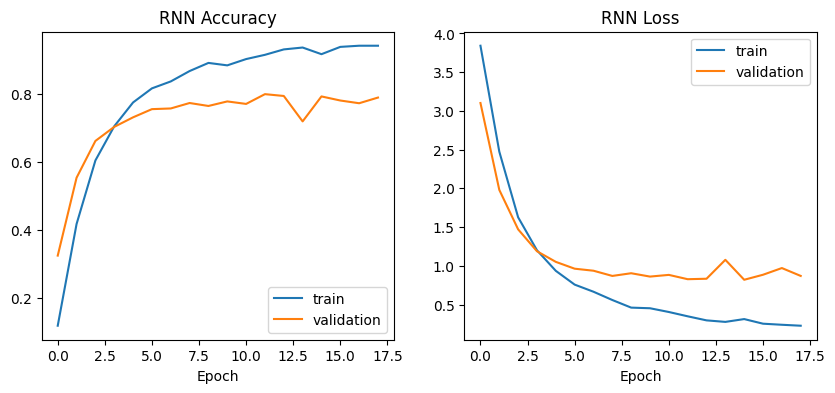

Validation loss: 0.8197
Validation accuracy: %79.25


In [46]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)                                   # sol grafik: doğruluk
plt.plot(rnn_history.history["accuracy"], label="train")
plt.plot(rnn_history.history["val_accuracy"], label="validation")
plt.title("RNN Accuracy"); plt.xlabel("Epoch"); plt.legend()

plt.subplot(1, 2, 2)                                   # sağ grafik: hata
plt.plot(rnn_history.history["loss"], label="train")
plt.plot(rnn_history.history["val_loss"], label="validation")
plt.title("RNN Loss"); plt.xlabel("Epoch"); plt.legend()

plt.show()

val_loss, val_accuracy = rnn_model.evaluate(
    X_val,
    y_val,
    verbose=0
)

print(f"Validation loss: {val_loss:.4f}")
print(f"Validation accuracy: %{val_accuracy * 100:.2f}")

Save to trained model

In [47]:
from pathlib import Path

Path("models").mkdir(exist_ok=True)
rnn_model.save("models/rnn_model.keras")

print("RNN modeli kaydedildi.")

RNN modeli kaydedildi.
